# M4. 보도자료 모으기(비정형 입문)

정부 부처 네 곳의 보도자료 RSS 를 직접 모아 MongoDB 문서로 적재하고, 날짜 형식을 맞춘 뒤 최근 7일 제목에 많이 나온 낱말을 집계합니다.

- 단계: 기초 미니 프로젝트 · 비정형 · 예상 3~4시간
- 실행 환경: Google Colab(브라우저만 있으면 됩니다)
- 데이터: 과학기술정보통신부 · 보건복지부 · 행정안전부 · 농림축산식품부 — 보도자료 RSS(2026-10-28 22시 수집 스냅샷 155건, 각 부처 보도자료 화면에 공공누리 제1유형(출처표시) 표시)

셀을 위에서부터 차례로 실행하세요. 각 단계 끝의 **확인 포인트** 숫자가 같게 나오면 다음 단계로 갑니다.
따라하기를 한 번 끝냈다면 같은 내용의 [빈칸 노트북](https://colab.research.google.com/github/aebonlee/materials/blob/main/data-eng/projects/M4/M4_blank.ipynb)으로 다시 쳐 보세요.

정부 부처는 하루에도 몇 건씩 보도자료를 냅니다. 이 프로젝트에서는 부처 네 곳의 보도자료 RSS 를 모아 **「최근 7일 동안 정부가 가장 많이 말한 낱말은 무엇인가」**를 숫자로 답합니다.

RSS 는 표가 아니라 「글 묶음」입니다. 부처마다 날짜를 적는 방식이 다르고, 본문 요약이 있는 곳도 없는 곳도 있습니다.
이렇게 모양이 제각각인 데이터를 담는 연습이 이 프로젝트의 핵심입니다 — 비정형 데이터의 첫걸음입니다.

```text
RSS 4곳(실시간) → 문서(dict) → 날짜 맞추기 → MongoDB 컬렉션 → 집계 파이프라인 → 낱말 빈도
```

다 끝내면 다음 세 가지를 말할 수 있습니다.

- 부처마다 다른 날짜 형식을 하나로 맞추는 방법과, 라이브러리가 **조용히 틀리는** 경우
- MongoDB 에 같은 글이 두 번 들어가지 않게 막는 방법
- RSS 가 「최근 몇십 건」만 주기 때문에, 한 주를 빠짐없이 담으려면 무엇이 필요한지

## 1단계 · 준비 — 라이브러리와 데이터

RSS 는 `feedparser` 로 읽고, MongoDB 는 `mongomock` 으로 씁니다.
Colab 에는 MongoDB 서버가 없습니다. `mongomock` 은 pymongo 와 똑같은 명령(`insert_many` · `find` · `aggregate`)을 메모리 안에서 흉내 내는 라이브러리라, 같은 코드가 내 컴퓨터의 진짜 MongoDB 에서도 그대로 돕니다(2주차 9장).

수집은 실시간으로 하지만, RSS 는 매일 바뀌어 오늘 받은 숫자가 내일과 다릅니다.
그래서 2026년 10월 28일 22시에 같은 코드로 받아 둔 스냅샷(155건)을 함께 씁니다. 4단계부터의 확인 포인트 숫자는 이 스냅샷 기준입니다.

출처는 과학기술정보통신부 · 보건복지부 · 행정안전부 · 농림축산식품부의 보도자료 RSS 입니다.
네 부처 모두 보도자료 화면 아래에 **공공누리 제1유형(출처표시)** 이 붙어 있어, 출처를 밝히면 내려받아 다시 나눠 쓸 수 있습니다.

In [ ]:
import sys, subprocess, importlib.util
def need(mod, pkg=None):
    if importlib.util.find_spec(mod) is None:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", pkg or mod], check=True)
need("feedparser")
need("mongomock")

import os, re, json, time, shutil, urllib.request
import datetime as dt
import requests, feedparser
import pandas as pd

DATA = "https://raw.githubusercontent.com/aebonlee/materials/main/data-eng/projects/data/"

def fetch(name):
    """프로젝트 데이터를 ./data 폴더에 한 번만 받아 둡니다."""
    os.makedirs("data", exist_ok=True)
    dst = os.path.join("data", name)
    if not os.path.exists(dst):
        local = os.environ.get("DE_DATA_LOCAL")          # 오프라인 실습용 — 자료 폴더가 내 컴퓨터에 있을 때
        if local:
            shutil.copy(os.path.join(local, name), dst)
        else:
            urllib.request.urlretrieve(DATA + name, dst)
    return dst

path = fetch("press_rss_20261028.jsonl")
print(path, round(os.path.getsize(path) / 1e3, 1), "KB")

data/press_rss_20261028.jsonl 101.6 KB


> **확인 포인트** — `data/press_rss_20261028.jsonl 101.6 KB` 가 찍힙니다.

## 2단계 · RSS 한 개 열어 보기 — robots.txt 부터

남의 사이트에서 가져올 때는 먼저 문 앞의 안내문(robots.txt)을 읽습니다(2주차 11장).
그리고 요청에 브라우저 이름(User-Agent)을 붙입니다. 일부 기관 서버는 이름 없는 요청을 막습니다.

In [ ]:
from urllib.robotparser import RobotFileParser

UA = {"User-Agent": "Mozilla/5.0 (Macintosh; Intel Mac OS X 10_15_7) AppleWebKit/537.36 Chrome/130 Safari/537.36"}
MSIT = "https://www.msit.go.kr/user/rss/rss.do?bbsSeqNo=94"

rp = RobotFileParser()
try:
    rp.parse(requests.get("https://www.msit.go.kr/robots.txt", headers=UA, timeout=20).text.splitlines())
    print("수집해도 되나:", rp.can_fetch("*", MSIT))
except requests.RequestException as e:
    print("robots.txt 를 받지 못했습니다:", type(e).__name__)

수집해도 되나: True


이제 과학기술정보통신부 보도자료 RSS 를 엽니다. RSS 는 XML 이지만 `feedparser` 가 글 하나하나를 dict 처럼 꺼내 줍니다.

In [ ]:
try:
    r = requests.get(MSIT, headers=UA, timeout=30)
    feed = feedparser.parse(r.content)
    print(r.status_code, feed.feed.get("title"), len(feed.entries), "건")
    e = feed.entries[0]
    print(list(e.keys()))
    print(e["title"], "|", e["published"])
except requests.RequestException as ex:
    feed = None
    print("지금은 접속되지 않습니다:", type(ex).__name__, "— 4단계의 스냅샷으로 계속하세요.")

200 보도자료 50 건
['title', 'title_detail', 'links', 'link', 'content', 'summary', 'published', 'published_parsed']
AI로 이룬 공공혁신, 국민이 누리는 변화 「2026 공공기관 AI 혁신 성과대회」 개최 | 2026.10.28


> **확인 포인트** — 상태 `200`, 제목 `보도자료`, 50건 안팎이 찍힙니다. 글마다 `title` · `link` · `published` · `summary` 가 있습니다.
> 실시간 데이터라 건수와 첫 글은 날마다 다릅니다.

In [ ]:
if feed is not None:
    assert len(feed.entries) >= 1
    assert {"title", "link", "published"} <= set(feed.entries[0].keys())

일부러 실패해 봅니다. 인터넷에 많이 퍼져 있는 정책브리핑(korea.kr)의 보도자료 RSS 주소입니다.

In [ ]:
try:
    r = requests.get("https://www.korea.kr/rss/pressrelease.xml", headers=UA, timeout=20)
    print(r.status_code, len(feedparser.parse(r.content).entries), "건")
except requests.RequestException as ex:
    print("접속 실패:", type(ex).__name__)

404 0 건


`404` 에 0건입니다. 정책브리핑은 2026년 7월 1일 「콘텐츠 저작권 등 권리 보호」를 이유로 RSS 서비스를 끝냈습니다(정책브리핑 공지사항).
그래서 이 프로젝트는 보도자료를 낸 부처의 RSS 에서 직접 받습니다.

> **Aebon's Tip** — 검색해서 찾은 수집 주소는 먼저 한 번 열어 보세요. 공공기관 RSS 는 주소가 자주 바뀌고, 이번처럼 서비스가 끝나기도 합니다.
> 각 부처 누리집 맨 아래 「RSS」 링크가 가장 믿을 만한 출처입니다.

> **자주 겪는 오류** — Colab 서버는 해외에 있습니다. 일부 기관 누리집은 해외 접속을 막아 `ConnectTimeout` 이 날 수 있습니다.
> 그럴 때는 2~3단계를 읽기만 하고, 4단계의 스냅샷으로 이어서 하세요.

## 3단계 · 네 부처 모으기 — 그리고 날짜가 어긋나는 것 보기

부처 네 곳의 RSS 를 차례로 받아 **같은 모양의 dict(문서)** 로 바꿉니다. 요청 사이에 1초씩 쉬어 서버에 부담을 주지 않습니다.
본문 요약(`summary`)은 HTML 태그를 지우고 앞 300자만 남깁니다.

In [ ]:
import html

FEEDS = {
    "msit":  ("과학기술정보통신부", "https://www.msit.go.kr/user/rss/rss.do?bbsSeqNo=94"),
    "mohw":  ("보건복지부", "https://www.mohw.go.kr/rss/board.es?mid=a10503000000&bid=0027"),
    "mois":  ("행정안전부", "https://www.mois.go.kr/gpms/view/jsp/rss/rss.jsp?ctxCd=1012"),
    "mafra": ("농림축산식품부", "https://www.mafra.go.kr/bbs/home/792/rssList.do?row=50"),
}

def clean(t):
    """HTML 태그 · 주석과 &amp; 같은 기호를 지우고 공백을 한 칸으로."""
    t = html.unescape(t or "")                       # 요약이 &lt;p&gt; 처럼 한 번 더 감싸여 오는 부처가 있습니다
    t = re.sub(r"<!--.*?-->", " ", t, flags=re.S)     # 한글 문서에서 붙여 넣은 숨은 주석
    t = html.unescape(re.sub(r"<[^>]+>", " ", t))
    return re.sub(r"\s+", " ", t).strip()

def collect(source):
    agency, url = FEEDS[source]
    r = requests.get(url, headers=UA, timeout=30)
    r.raise_for_status()
    docs = []
    for e in feedparser.parse(r.content).entries:
        docs.append({
            "source": source, "agency": agency,
            "title": clean(e.get("title")), "link": e.get("link", "").strip(),
            "published": e.get("published", ""),            # 부처가 적은 글자 그대로 — 4단계에서 맞춥니다
            "summary": clean(e.get("summary"))[:300],
        })
    return docs

live = []
for s in FEEDS:
    try:
        got = collect(s)
        live += got
        print(s, len(got), "건 |", got[0]["published"] if got else "-")
    except requests.RequestException as ex:
        print(s, "실패:", type(ex).__name__)
    time.sleep(1)
print("모은 문서:", len(live))

msit 50 건 | 2026.10.28


mohw 30 건 | Wed, 28 Oct 2026 07:50:00 GMT


mois 25 건 | WED, 28 OCT 2026 14:00:00 KST


mafra 50 건 | 2026-10-28 09:24:28.242


모은 문서: 155


> **확인 포인트** — 네 줄에 부처마다 건수와 첫 글의 날짜가 찍힙니다. 날짜 글자를 보세요 — `2026.10.28` · `Wed, 28 Oct 2026 07:50:00 GMT` · `수, 28 10월 2026 14:00:00 KST` · `2026-10-28 09:24:28.242` 처럼 부처마다 다릅니다.

In [ ]:
if live:
    assert {"source", "agency", "title", "link", "published", "summary"} == set(live[0])
    assert all(d["link"].startswith("http") for d in live)

이 날짜들을 pandas 로 한 번에 날짜형으로 바꿔 봅니다. 일부러 실패하는 셀입니다.

In [ ]:
samples = ["2026.10.28", "Wed, 28 Oct 2026 07:50:00 GMT", "수, 28 10월 2026 14:00:00 KST", "2026-10-28 09:24:28.242"]
try:
    print(pd.to_datetime(samples))
except ValueError as e:
    print("변환 실패:", str(e)[:90])

변환 실패: time data "Wed, 28 Oct 2026 07:50:00 GMT" doesn't match format "%Y.%m.%d", at position 1. 


pandas 는 첫 글자 모양(`%Y.%m.%d`)을 보고 나머지도 같다고 여기다가 두 번째에서 멈춥니다.
`feedparser` 도 날짜를 풀어 주지만(`published_parsed`), 더 위험한 방식으로 틀립니다.

In [ ]:
from feedparser.datetimes import _parse_date
for s in samples:
    t = _parse_date(s)
    print(f"{s:32} → {time.strftime('%Y-%m-%d %H:%M', t) if t else None}")

2026.10.28                       → 2026-10-01 00:00
Wed, 28 Oct 2026 07:50:00 GMT    → 2026-10-28 07:50
수, 28 10월 2026 14:00:00 KST      → None
2026-10-28 09:24:28.242          → 2026-10-28 09:24


`2026.10.28` 이 **2026-10-01** 로 바뀌었습니다. 오류도 없이 날짜만 틀립니다. 한국어 요일 · 월 이름은 아예 `None` 이 되고, `GMT` 는 한국 시각보다 9시간 이릅니다.
멈추는 오류보다 **조용히 틀리는 값**이 더 위험합니다. 그래서 다음 단계에서 날짜 맞추는 함수를 직접 씁니다.

## 4단계 · 스냅샷 불러오기와 날짜 맞추기

여기서부터는 스냅샷으로 진행합니다. 3단계의 `live` 와 열이 같습니다(받은 시각 `collected_at` 하나만 더 있습니다).
JSONL 은 한 줄에 JSON 문서 하나를 적은 파일입니다. 문서형 데이터를 파일로 주고받을 때 가장 흔한 모양입니다.

In [ ]:
docs = []
with open(path, encoding="utf-8") as f:
    for line in f:
        docs.append(json.loads(line))
print(len(docs), "건")
print(pd.Series([d["source"] for d in docs]).value_counts().to_dict())
docs[0]

155 건
{'msit': 50, 'mafra': 50, 'mohw': 30, 'mois': 25}


{'source': 'msit',
 'agency': '과학기술정보통신부',
 'title': 'AI로 이룬 공공혁신, 국민이 누리는 변화 「2026 공공기관 AI 혁신 성과대회」 개최',
 'link': 'https://www.msit.go.kr/bbs/view.do?sCode=user&bbsSeqNo=94&nttSeqNo=3187898',
 'published': '2026.10.28',
 'summary': '- 공공기관, AI 혁신 주체로 민생 체감 서비스와 행정 효율화 성과 창출- 30개 혁신 우수과제 선정... 공공행정 AI 전환 첫걸음 내뎌 - 한국서부발전 ‘AI 운영 K-가스터빈’, 인천국제공항공사 ‘AI 기반 항공 안전관리’ 대상 수상',
 'collected_at': '2026-10-28T22:26:27+09:00'}

> **확인 포인트** — 155건 — 과기정통부 50 · 농식품부 50 · 복지부 30 · 행안부 25. 부처마다 RSS 가 주는 건수가 다릅니다.

In [ ]:
assert len(docs) == 155

날짜 형식은 네 가지입니다. 하나씩 정규식으로 알아보고, 모두 **한국 시각(KST)** 으로 맞춥니다.

In [ ]:
import email.utils
KST = dt.timezone(dt.timedelta(hours=9))

def parse_date(s):
    s = s.strip()
    m = re.match(r"(\d{4})[.-](\d{2})[.-](\d{2})(?: (\d{2}):(\d{2}))?", s)      # 2026.10.28 · 2026-10-28 09:24:28
    if m:
        y, mo, d, h, mi = m.groups()
        return dt.datetime(int(y), int(mo), int(d), int(h or 0), int(mi or 0))
    m = re.match(r"\S+, (\d{1,2}) (\d{1,2})월 (\d{4}) (\d{2}):(\d{2})", s)      # 수, 28 10월 2026 14:00:00 KST
    if m:
        d, mo, y, h, mi = map(int, m.groups())
        return dt.datetime(y, mo, d, h, mi)
    t = email.utils.parsedate_to_datetime(s)            # Wed, 28 Oct 2026 07:50:00 GMT
    return t.astimezone(KST).replace(tzinfo=None)

for s in samples:
    print(f"{s:32} → {parse_date(s)}")

2026.10.28                       → 2026-10-28 00:00:00
Wed, 28 Oct 2026 07:50:00 GMT    → 2026-10-28 16:50:00
수, 28 10월 2026 14:00:00 KST      → 2026-10-28 14:00:00
2026-10-28 09:24:28.242          → 2026-10-28 09:24:00


> **확인 포인트** — 네 가지가 모두 2026-10-28 로 바뀌고, `07:50 GMT` 는 `16:50` 이 됩니다.

In [ ]:
assert parse_date("Wed, 28 Oct 2026 07:50:00 GMT") == dt.datetime(2026, 10, 28, 16, 50)
assert parse_date("2026.10.28") == dt.datetime(2026, 10, 28)

for d in docs:
    d["pub_at"] = parse_date(d["published"])
print(min(d["pub_at"] for d in docs), "~", max(d["pub_at"] for d in docs))

2026-10-06 00:00:00 ~ 2026-10-28 16:50:00


> **확인 포인트** — 155건 모두 바뀌고, 가장 오래된 글은 2026-10-06, 가장 새 글은 2026-10-28 16:50 입니다.

In [ ]:
assert min(d["pub_at"] for d in docs) == dt.datetime(2026, 10, 6)
assert max(d["pub_at"] for d in docs) == dt.datetime(2026, 10, 28, 16, 50)

> **자주 겪는 오류** — 과기정통부 RSS 는 시각 없이 날짜만 줍니다(00:00 으로 들어갑니다). 「몇 시에 나왔나」를 셀 때는 과기정통부를 빼야 합니다.

## 5단계 · MongoDB 에 적재 — 같은 글은 한 번만

MySQL 처럼 표를 먼저 만들 필요가 없습니다. 데이터베이스 · 컬렉션 이름을 부르면 첫 문서가 들어갈 때 생깁니다(2주차 9장).
다만 같은 RSS 를 내일 또 모으면 어제 글이 다시 옵니다. **링크에 유일 인덱스**를 걸어 같은 글이 두 번 들어가지 않게 합니다.

In [ ]:
import mongomock, pymongo

MONGO_URL = os.environ.get("MONGO_URL")          # 내 컴퓨터의 MongoDB 를 쓸 때: mongodb://localhost:27017
client = pymongo.MongoClient(MONGO_URL) if MONGO_URL else mongomock.MongoClient()
col = client["pressdb"]["press"]
col.drop()                                        # 다시 돌려도 처음부터 — 실습용

for d in docs:                                    # 요약이 없는 글은 summary 칸 자체를 두지 않습니다
    if not d["summary"]:
        d.pop("summary")

col.create_index("link", unique=True)
res = col.insert_many([dict(d) for d in docs])
print("넣은 문서:", len(res.inserted_ids), "| 컬렉션:", col.count_documents({}))

넣은 문서: 155 | 컬렉션: 155


`dict(d)` 로 복사해서 넣는 이유: pymongo 는 넣은 dict 에 `_id` 를 덧붙입니다. 원본 `docs` 를 깨끗하게 두려는 것입니다.

일부러 같은 글을 한 번 더 넣어 봅니다.

In [ ]:
try:
    col.insert_one(dict(docs[0]))
except pymongo.errors.DuplicateKeyError as e:
    print("막혔습니다:", type(e).__name__)
print("컬렉션:", col.count_documents({}))

막혔습니다: DuplicateKeyError
컬렉션: 155


> **확인 포인트** — `DuplicateKeyError` 로 막히고 컬렉션은 그대로 **155건**입니다.

In [ ]:
assert col.count_documents({}) == 155

이번에는 문서형 저장의 특징을 봅니다. 요약이 있는 글과 없는 글이 한 컬렉션에 함께 있습니다 — 표였다면 빈칸(NULL)이 되었을 자리입니다.

In [ ]:
with_sum = col.count_documents({"summary": {"$exists": True}})
print("요약 있음:", with_sum, "| 요약 없음:", col.count_documents({}) - with_sum)
print(col.find_one({"source": "mafra"}, {"_id": 0, "title": 1, "summary": 1}))

요약 있음: 90 | 요약 없음: 65
{'title': '김종구 차관, 아세안+3 농림장관회의 및 스마트팜 MOU 체결을 위해 싱가포르 방문'}


> **확인 포인트** — 요약 있는 글 **90건**, 없는 글 65건입니다. 농식품부 RSS 는 50건 모두 제목과 링크만 주고, 과기정통부도 15건은 요약이 비어 있습니다.
> 같은 부처 안에서도 문서 모양이 다릅니다.

In [ ]:
assert with_sum == 90

> **Aebon's Tip** — 내 컴퓨터에서는 2주차 9장의 MongoDB 컨테이너를 띄우고 환경 변수만 주면 같은 코드가 진짜 MongoDB 에 넣습니다.
> `docker run -d --name de-mongo -p 27017:27017 mongo:7.0` 뒤에 `MONGO_URL=mongodb://localhost:27017` 로 Jupyter 를 켜세요. mongosh 에서 `use pressdb` → `db.press.countDocuments()` 로 155 를 확인할 수 있습니다.

## 6단계 · 수집 범위 확인 — 「한 주」가 다 들어 있나

RSS 는 최근 글 몇십 건만 줍니다. 그래서 부처마다 **담긴 기간**이 다릅니다. 최근 7일(10/22~10/28)을 세기 전에 부처마다 가장 오래된 글과 새 글을 봅니다.
MongoDB 의 집계 파이프라인 `$group` 으로 셉니다 — SQL 의 `GROUP BY` 와 같은 일을 합니다.

In [ ]:
span = list(col.aggregate([
    {"$group": {"_id": "$source", "n": {"$sum": 1},
                "first": {"$min": "$pub_at"}, "last": {"$max": "$pub_at"}}},
    {"$sort": {"_id": 1}},
]))
pd.DataFrame(span)

,n,first,last,_id
0,50,2026-10-14 08:35:00,2026-10-28 09:24:00,mafra
1,30,2026-10-19 12:05:00,2026-10-28 16:50:00,mohw
2,25,2026-10-22 12:00:00,2026-10-28 14:00:00,mois
3,50,2026-10-06 00:00:00,2026-10-28 00:00:00,msit


> **확인 포인트** — 가장 오래된 글이 과기정통부 10/06 · 농식품부 10/14 · 복지부 10/19 인데, **행안부는 10/22 12:00** 입니다.

In [ ]:
first = {s["_id"]: s["first"] for s in span}
assert first["mois"] == dt.datetime(2026, 10, 22, 12, 0)
assert first["msit"] == dt.datetime(2026, 10, 6)

행안부 RSS 는 25건만 주어서 10/22 오전 이전 글이 잘렸을 수 있습니다. 가장 오래된 글이 세는 기간의 첫날(10/22) 안에 있으면 그날이 다 들어 있는지 알 수 없습니다.
그래서 낱말을 셀 때는 **기간이 모두 담긴 세 부처**(과기정통부 · 복지부 · 농식품부)만 씁니다.

In [ ]:
W0, W1 = dt.datetime(2026, 10, 22), dt.datetime(2026, 10, 29)      # 10/22 00:00 이상, 10/29 00:00 미만
complete = [s for s, t in first.items() if t < W0]
week = {"pub_at": {"$gte": W0, "$lt": W1}, "source": {"$in": complete}}
print("기간이 다 담긴 부처:", sorted(complete), "| 최근 7일 글:", col.count_documents(week))

기간이 다 담긴 부처: ['mafra', 'mohw', 'msit'] | 최근 7일 글: 57


> **확인 포인트** — `['mafra', 'mohw', 'msit']` 세 부처, 최근 7일 글 **57건**입니다.

In [ ]:
assert sorted(complete) == ["mafra", "mohw", "msit"] and col.count_documents(week) == 57

> **Aebon's Tip** — 빈틈 없이 담으려면 RSS 를 **매일** 모아 5단계처럼 유일 인덱스로 쌓으면 됩니다. 매일 돌리는 일은 8주차 Airflow 가 맡습니다.

## 7단계 · 키워드 빈도 — 형태소 분석기 없이

제목을 낱말로 나눕니다. 형태소 분석기 없이 간단한 규칙 세 가지로 합니다.

1. 한글 2글자 이상, 또는 영문 2글자 이상을 낱말로 봅니다(정규식).
2. 낱말 끝의 조사(`의` · `를` · `에서` …)를 한 번 떼어 냅니다 — `미래를` 과 `미래` 를 같은 낱말로 세려는 것입니다. 남는 글자가 2글자 이상일 때만 뗍니다.
3. 뜻이 없는 낱말(`개최` · `위한` …)과 부처 이름은 불용어로 뺍니다. `인공지능` 은 `AI` 로 합칩니다.

In [ ]:
JOSA = ("으로", "에서", "에게", "부터", "까지", "의", "를", "을", "에", "은", "는", "이", "가", "로", "와", "과", "도")
STOP = {"개최", "위해", "위한", "대한", "통해", "관련", "추진", "실시", "시작",
        "과기정통부", "농식품부", "복지부", "행안부", "장관", "차관", "국민"}
SAME = {"인공지능": "AI"}

def words(title):
    out = []
    for w in re.findall(r"[가-힣]{2,}|[A-Za-z]{2,}", title):
        if w.isascii():
            w = w.upper()
        else:
            for j in JOSA:
                if w.endswith(j) and len(w) - len(j) >= 2:
                    w = w[:-len(j)]
                    break
        w = SAME.get(w, w)
        if w not in STOP:
            out.append(w)
    return out

print(words("AI로 이룬 공공혁신, 국민이 누리는 변화 「2026 공공기관 AI 혁신 성과대회」 개최"))

['AI', '이룬', '공공혁신', '누리', '변화', '공공기관', 'AI', '혁신', '성과대회']


> **확인 포인트** — `['AI', '이룬', '공공혁신', '누리', '변화', '공공기관', 'AI', '혁신', '성과대회']` — `국민이` 는 조사를 뗀 뒤 불용어로 빠지고, `개최` 도 빠집니다.
> `누리는` 이 `누리` 가 된 것처럼 규칙이 틀리는 곳도 있습니다. 간단한 규칙의 한계입니다.

In [ ]:
assert words("AI로 이룬 공공혁신, 국민이 누리는 변화 「2026 공공기관 AI 혁신 성과대회」 개최") == \
    ["AI", "이룬", "공공혁신", "누리", "변화", "공공기관", "AI", "혁신", "성과대회"]

낱말 목록을 문서마다 `words` 칸에 넣습니다. 문서형이라 칸을 나중에 더해도 됩니다.

In [ ]:
for d in col.find({}, {"title": 1}):
    col.update_one({"_id": d["_id"]}, {"$set": {"words": words(d["title"])}})
print(col.find_one({}, {"_id": 0, "title": 1, "words": 1}))

{'title': 'AI로 이룬 공공혁신, 국민이 누리는 변화 「2026 공공기관 AI 혁신 성과대회」 개최', 'words': ['AI', '이룬', '공공혁신', '누리', '변화', '공공기관', 'AI', '혁신', '성과대회']}


이제 최근 7일 · 세 부처 문서만 골라(`$match`), 낱말 목록을 한 줄에 하나씩 펼치고(`$unwind`), 낱말마다 셉니다(`$group`).
같은 횟수면 낱말 가나다순으로 놓아 순서가 늘 같게 합니다.

In [ ]:
top = list(col.aggregate([
    {"$match": week},
    {"$unwind": "$words"},
    {"$group": {"_id": "$words", "n": {"$sum": 1}}},
    {"$sort": {"n": -1, "_id": 1}},
    {"$limit": 10},
]))
top10 = pd.DataFrame(top).rename(columns={"_id": "word"})[["word", "n"]]
top10

,word,n
0,AI,11
1,미래,7
2,지역,4
3,치료,4
4,혁신,4
5,공포,3
6,국제,3
7,대한민국,3
8,변화,3
9,한국,3


> **확인 포인트** — 1위 **AI 11번**(`인공지능` 6 + `AI` 5), 2위 미래 7번, 3위 지역 · 치료 · 혁신 4번입니다.

In [ ]:
assert top10.iloc[0].tolist() == ["AI", 11] and top10.iloc[1].tolist() == ["미래", 7]
assert top10["n"].tolist()[:5] == [11, 7, 4, 4, 4]

같은 답을 파이썬 `Counter` 로도 내 봅니다. 두 방법이 같은 숫자를 내면 파이프라인을 믿을 수 있습니다.

In [ ]:
from collections import Counter
c = Counter()
for d in col.find(week, {"words": 1}):
    c.update(d["words"])
print(c.most_common(3), "| 낱말 수:", sum(c.values()), "| 서로 다른 낱말:", len(c))
assert c["AI"] == 11 and c["미래"] == 7

[('AI', 11), ('미래', 7), ('혁신', 4)] | 낱말 수: 465 | 서로 다른 낱말: 396


> **자주 겪는 오류** — `$sort` 에 `_id` 를 함께 주지 않으면 횟수가 같은 낱말의 순서가 실행할 때마다 달라질 수 있습니다. 순위를 assert 하거나 보고서에 쓸 때는 정렬 기준을 끝까지 정하세요.

> **Aebon's Tip** — 형태소 분석기(예: kiwipiepy)를 쓰면 `누리는 → 누리다` 처럼 낱말 원형을 찾아 줍니다. 이 프로젝트의 규칙과 결과를 비교해 보면 「간단한 규칙이 어디서 틀리는지」가 보입니다.

## 8단계 · 저장과 그래프

결과를 파일로 남깁니다. 문서는 JSONL 로 다시 내보내고(날짜는 ISO 글자로), 낱말 순위는 CSV 로 저장합니다.

In [ ]:
os.makedirs("out", exist_ok=True)
with open("out/press_clean.jsonl", "w", encoding="utf-8") as f:
    for d in col.find({}, {"_id": 0}):
        f.write(json.dumps(d, ensure_ascii=False, default=str) + "\n")
top10.to_csv("out/top10_words.csv", index=False)

back = sum(1 for _ in open("out/press_clean.jsonl", encoding="utf-8"))
print("다시 읽은 문서:", back)
assert back == 155

다시 읽은 문서: 155


날짜별 · 부처별 보도자료 수를 그립니다. 그래프 글자는 영어로 둡니다(Colab 기본 글꼴에 한글이 없습니다).

[12, 8, 0, 0, 17, 8, 12]


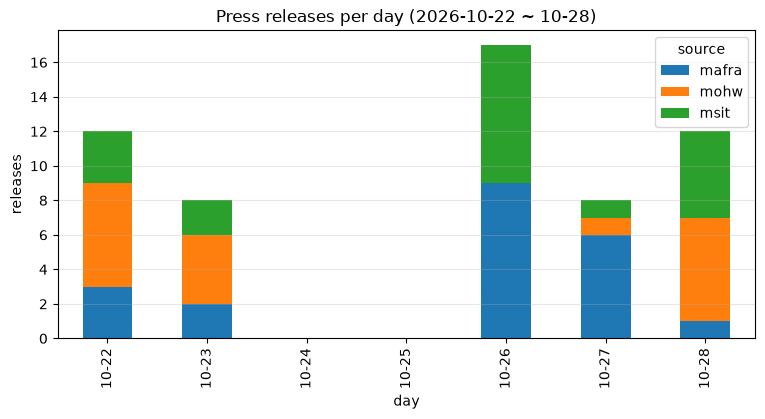

In [ ]:
import matplotlib.pyplot as plt

daily = pd.DataFrame(col.find(week, {"_id": 0, "source": 1, "pub_at": 1}))
daily["day"] = daily["pub_at"].dt.strftime("%m-%d")
days = pd.date_range(W0, periods=7).strftime("%m-%d")          # 글이 없는 날도 0 으로 보이게
table = daily.groupby(["day", "source"]).size().unstack(fill_value=0).reindex(days, fill_value=0)
print(table.sum(axis=1).tolist())

table.plot(kind="bar", stacked=True, figsize=(9, 4))
plt.title("Press releases per day (2026-10-22 ~ 10-28)")
plt.xlabel("day")
plt.ylabel("releases")
plt.grid(axis="y", alpha=.3)
plt.show()

> **확인 포인트** — 날짜별 합계가 `[12, 8, 0, 0, 17, 8, 12]` 입니다. 주말인 10/24(토) · 10/25(일)은 0건이고, 월요일(10/26)이 17건으로 가장 많습니다.
> `reindex` 를 빼면 글이 없는 주말이 그래프에서 아예 사라져 「쉰 날」이 보이지 않습니다.

In [ ]:
assert table.sum(axis=1).tolist() == [12, 8, 0, 0, 17, 8, 12]

## 9단계 · 더 해 보기

- 3단계의 `live` 를 같은 컬렉션에 `insert_many(..., ordered=False)` 로 넣어 보세요. 이미 있는 글은 `BulkWriteError` 로 건너뛰고 새 글만 들어갑니다. 며칠 동안 매일 하면 행안부의 빈틈이 메워집니다.
- 제목 대신 요약(`summary`)으로 낱말을 세면 순위가 어떻게 바뀌나요? 요약이 없는 농식품부는 어떻게 다룰지 정해 보세요.
- 부처마다 1위 낱말을 뽑아 보세요(`$group` 을 `source` 와 `words` 두 칸으로).
- 보도자료에 붙은 PDF 까지 모아 본문을 검색하면 P5(보도자료 요약 · 검색기)가 됩니다.